# 03 · Reglas de asociación — SportSmart Perú

¿Qué productos se compran conjuntamente y cuáles tienen mayor asociación? Se comparan Apriori, FP-Growth y ECLAT sobre las canastas de pedidos válidos.

**Criterio de éxito:** lift > 1,5 con soporte ≥ 1 %, por subcategoría.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
from src.models import asociacion
from src.data.estilo_graficos import AZUL, NARANJA, aplicar_estilo, barras_h, guardar, numero
aplicar_estilo()
res = asociacion.main()
print(res['canastas'])

{'pedidos': 60300, 'subcategorias': 20, 'items_por_pedido': 1.62, 'pct_multi_subcategoria': 43.2}


## 1. Por qué se trabaja por subcategoría

In [2]:
print(res['nivel_producto'])
print(f"El par de productos más frecuente aparece en {res['nivel_producto']['pedidos_max_par']} de {numero(res['canastas']['pedidos'], 0)} pedidos: {numero(res['nivel_producto']['soporte_max_par_pct'], 3)} %.")

{'productos': 321, 'soporte_max_producto_pct': 1.285, 'soporte_max_par_pct': 0.035, 'pedidos_max_par': 21}
El par de productos más frecuente aparece en 21 de 60 300 pedidos: 0,035 %.


Con 321 productos, cada par coincide en muy pocos pedidos y ninguno se acerca al soporte mínimo de 1 %. Las 20 subcategorías concentran suficientes casos para obtener reglas confiables.

## 2. Comparación de algoritmos

Los tres resuelven el mismo problema de forma exacta, por lo que deben encontrar los mismos conjuntos. La diferencia está en el costo.

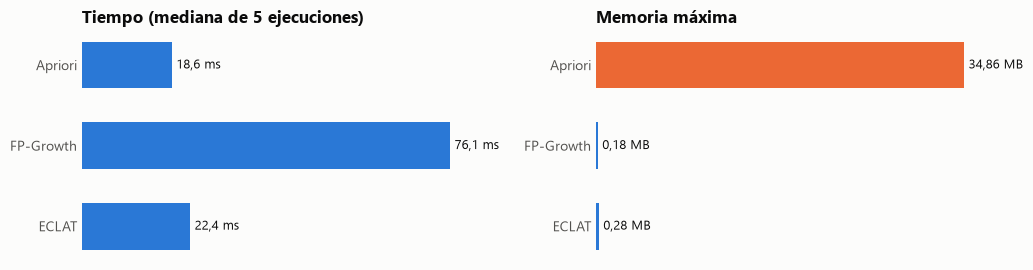

Resultados idénticos en todos los soportes: True


,soporte_min,algoritmo,conjuntos,segundos,memoria_mb,resultados_identicos
0,0.020,Apriori,32,0.0155,31.42,True
1,0.020,FP-Growth,32,0.0753,0.14,True
2,0.020,ECLAT,32,0.0154,0.21,True
3,0.010,Apriori,60,0.0186,34.86,True
4,0.010,FP-Growth,60,0.0761,0.18,True
5,0.010,ECLAT,60,0.0224,0.28,True
6,0.005,Apriori,89,0.0232,34.86,True
7,0.005,FP-Growth,89,0.0759,0.23,True
8,0.005,ECLAT,89,0.0292,0.28,True
9,0.002,Apriori,144,0.0319,48.61,True


In [3]:
comp = pd.DataFrame(res['comparacion']); a = comp[comp.soporte_min == 0.01].set_index('algoritmo')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 2.8))
barras_h(a1, list(a.index), list(a.segundos * 1000), AZUL, lambda v: numero(v) + ' ms'); a1.set_title('Tiempo (mediana de 5 ejecuciones)')
barras_h(a2, list(a.index), list(a.memoria_mb), [NARANJA, AZUL, AZUL], lambda v: numero(v, 2) + ' MB'); a2.set_title('Memoria máxima')
guardar(fig, 'comparacion_asociacion')
print('Resultados idénticos en todos los soportes:', bool(comp.resultados_identicos.all()))
comp

## 3. Reglas obtenidas

{'soporte_min': 0.01, 'lift_min': 1.5, 'confianza_min': 0.2, 'total': 58, 'no_redundantes': 40, 'por_tamano_antecedente': {1: 31, 2: 27}, 'lift_max': 12.7, 'lift_mediana': 2.81, 'confianza_max': 1.0, 'soporte_max_pct': 3.41}


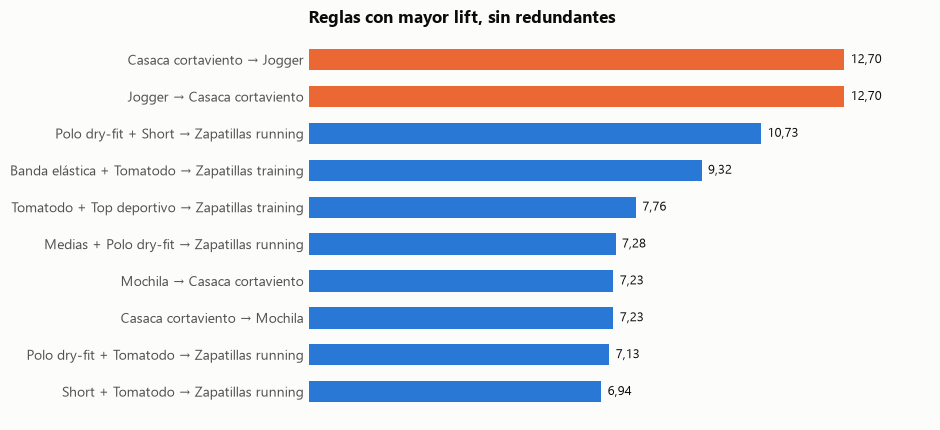

,antecedente,consecuente,soporte,confianza,lift
0,Casaca cortaviento,Jogger,0.0136,0.3267,12.7012
1,Jogger,Casaca cortaviento,0.0136,0.5287,12.7012
2,Mochila,Casaca cortaviento,0.0131,0.3008,7.2274
3,Casaca cortaviento,Mochila,0.0131,0.3135,7.2274
4,Mat de yoga,Banda elástica,0.0112,0.3279,6.1607
5,Banda elástica,Mat de yoga,0.0112,0.2113,6.1607
6,Banda elástica,Zapatillas training,0.0298,0.5597,5.9249
7,Zapatillas training,Banda elástica,0.0298,0.3153,5.9249
8,Chimpunes,Pelota,0.0256,0.3235,4.0773
9,Pelota,Chimpunes,0.0256,0.3225,4.0773


In [4]:
print(res['reglas'])
reglas = pd.read_csv(ROOT / 'reports' / 'reglas_asociacion.csv'); u = reglas[~reglas.redundante].head(10)
fig, ax = plt.subplots(figsize=(9.5, 4.4))
barras_h(ax, [f"{a} → {b}" for a, b in zip(u.antecedente, u.consecuente)], list(u.lift), [NARANJA] * 2 + [AZUL] * 8, lambda v: numero(v, 2))
ax.set_title('Reglas con mayor lift, sin redundantes')
guardar(fig, 'reglas_asociacion')
pd.DataFrame(res['top_pares'])

## 4. Validación temporal

Las reglas se descubren con pedidos hasta setiembre de 2025 y se comprueban en los 12 meses siguientes, que no se usaron para encontrarlas.

In [5]:
pd.Series(res['validacion_temporal'], name='valor').to_frame()

,valor
pedidos_entrenamiento,41296.000
pedidos_prueba,19004.000
reglas_entrenamiento,61.000
se_mantienen_lift,61.000
se_mantienen_soporte,54.000
se_mantienen_ambos,54.000
correlacion_lift,0.996
diferencia_media_confianza,0.017


## 5. Conclusiones y acciones

- **Meta cumplida:** 58 reglas superan lift 1,5 con soporte ≥ 1 %; 40 no son redundantes. El lift llega a 12,70.
- **Algoritmos:** los tres encuentran conjuntos idénticos en todos los soportes. Con 20 subcategorías la diferencia de tiempo es de milisegundos, mientras que Apriori usa más de 30 MB y los otros dos menos de 0,5 MB. Se usa FP-Growth en el flujo del proyecto por su bajo consumo de memoria y por estar disponible en una librería mantenida.
- **Estabilidad:** las 61 reglas descubiertas hasta setiembre de 2025 mantienen lift ≥ 1,5 en el año siguiente, 54 conservan además soporte ≥ 1 %, y la correlación entre los lifts es 0,996.

**Acciones propuestas:**

| Regla | Evidencia | Acción |
|---|---|---|
| Casaca cortaviento ↔ Jogger | Lift 12,70 | Paquete de temporada |
| Casaca cortaviento ↔ Mochila | Lift 7,23 | Recomendación en la ficha del producto |
| Mat de yoga ↔ Banda elástica | Lift 6,16 | Kit de yoga y entrenamiento en casa |
| Banda elástica → Zapatillas training | Confianza 56,0 % | Ofrecer calzado a quien compra accesorios de entrenamiento |
| Chimpunes ↔ Pelota | Lift 4,08 | Kit de fútbol |

**Limitación:** las reglas reflejan patrones incorporados al simular las canastas. Por ejemplo, la confianza de 100 % en *Polo dry-fit + Short → Zapatillas running* ocurre porque el generador solo combina esos artículos en canastas de running; en datos reales una regla así sería excepcional.